In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

In [2]:
def evaluate_clustering(X_data, labels, y_true, model_name, ignore_noise=False):
    """Computes Internal (Silhouette) and External (Purity & Entropy) indices."""
    if ignore_noise:
        mask = labels != -1
        X_eval, labels_eval, y_eval = X_data[mask], labels[mask], y_true[mask]
    else:
        X_eval, labels_eval, y_eval = X_data, labels, y_true

    unique_clusters = set(labels_eval)
    if len(unique_clusters) > 1 and len(unique_clusters) < len(X_eval):
        sil = silhouette_score(X_eval, labels_eval)
    else:
        sil = float("nan")

    # Contingency matrix (rows = predicted clusters, cols = true species)
    ct = pd.crosstab(labels_eval, y_eval).values
    n_total = ct.sum()

    # Purity: sum of max class count in each cluster / total samples
    purity = np.sum(np.max(ct, axis=1)) / n_total

    # Entropy: weighted sum of cluster entropies
    cluster_sizes = ct.sum(axis=1, keepdims=True)
    probs = ct / cluster_sizes
    # Avoid log2(0)
    log_probs = np.where(probs > 0, np.log2(probs), 0.0)
    cluster_entropies = -np.sum(probs * log_probs, axis=1)
    entropy = np.sum((cluster_sizes.flatten() / n_total) * cluster_entropies)

    print(f"{model_name}")
    print(f"Cluster distribution: {pd.Series(labels).value_counts().sort_index().to_dict()}")
    print(f"Silhouette Score: {sil:.4f}")
    print(f"Purity:           {purity:.4f}")

In [3]:
iris = sns.load_dataset("iris")
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

X_raw = iris[feature_cols].values
y = iris["species"].values

# Standardize features so all 4 measurements contribute equally to Euclidean distance
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print(f"Full Dataset Shape: {X.shape}")
print("Ground-Truth Class Counts:", pd.Series(y).value_counts().to_dict())

Full Dataset Shape: (150, 4)
Ground-Truth Class Counts: {'setosa': 50, 'versicolor': 50, 'virginica': 50}


**1) K-means:**

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

evaluate_clustering(X, kmeans_labels, y, "K-Means (K=3, n_init=10)")

K-Means (K=3, n_init=10)
Cluster distribution: {0: 53, 1: 50, 2: 47}
Silhouette Score: 0.4599
Purity:           0.8333


**2) AgglomerativeClustering:**

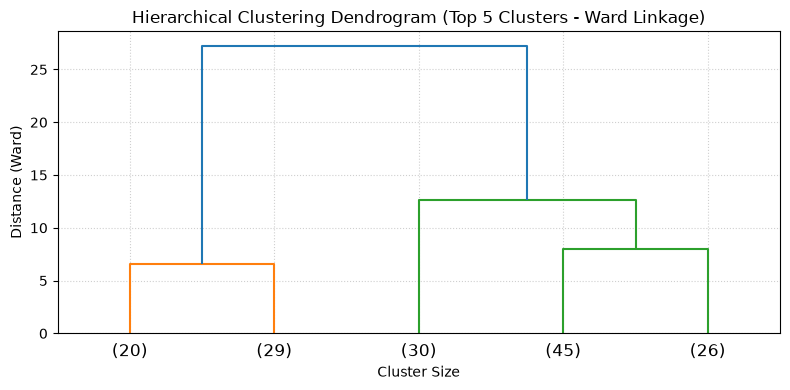

Agglomerative Clustering (Cut at K=3, Ward)
Cluster distribution: {0: 71, 1: 49, 2: 30}
Silhouette Score: 0.4467
Purity:           0.8267


In [5]:
Z = linkage(X, method="ward")

plt.figure(figsize=(8, 4))
dendrogram(Z, truncate_mode="lastp", p=5, show_leaf_counts=True)
plt.title("Hierarchical Clustering Dendrogram (Top 5 Clusters - Ward Linkage)")
plt.xlabel("Cluster Size")
plt.ylabel("Distance (Ward)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Cut down at 3 clusters
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
agg_labels = agg.fit_predict(X)

evaluate_clustering(X, agg_labels, y, "Agglomerative Clustering (Cut at K=3, Ward)")

**3) DBSCAN:**

In [6]:
# eps=0.6 and min_samples=5 on standardized Iris features separates dense core regions
dbscan = DBSCAN(eps=0.6, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)

# Report including noise (-1) as a group, and also excluding noise (-1)
evaluate_clustering(X, dbscan_labels, y, "DBSCAN (eps=0.6, min_samples=5) [All Points]", ignore_noise=False)
evaluate_clustering(X, dbscan_labels, y, "DBSCAN (eps=0.6, min_samples=5) [Core/Border Only]", ignore_noise=True)

DBSCAN (eps=0.6, min_samples=5) [All Points]
Cluster distribution: {-1: 26, 0: 46, 1: 78}
Silhouette Score: 0.4028
Purity:           0.6800
DBSCAN (eps=0.6, min_samples=5) [Core/Border Only]
Cluster distribution: {-1: 26, 0: 46, 1: 78}
Silhouette Score: 0.6419
Purity:           0.7097
